<a href="https://colab.research.google.com/github/renoegneo/MLclasswork/blob/main/sklnandasdsa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import files

uploaded = files.upload()

Saving bank-additional-full.csv to bank-additional-full.csv


In [6]:
import pandas as pd

df = pd.read_csv('bank-additional-full.csv', sep=';')

print("Размер датасета:", df.shape)
display(df.head())

Размер датасета: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [7]:
from sklearn.model_selection import train_test_split

# Удаляем duration, если он существует
if 'duration' in df.columns:
    df = df.drop(columns=['duration'])

# Проверяем пропуски
print("Пропуски:")
print(df.isnull().sum())

# Проверяем unknown
print("\nЗначения unknown:")
print((df == 'unknown').sum())

# Разделяем признаки и целевую переменную
X = df.drop(columns=['y'])
y = df['y']

# Делим на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nРазмер X_train:", X_train.shape)
print("Размер X_test:", X_test.shape)
print("Размер y_train:", y_train.shape)
print("Размер y_test:", y_test.shape)

print("\nПодготовка данных завершена!")

Пропуски:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Значения unknown:
age                  0
job                330
marital             80
education         1731
default           8597
housing            990
loan               990
contact              0
month                0
day_of_week          0
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
y                    0
dtype: int64

Размер X_train: (32950, 19)
Размер X_test: (8238, 19)
Размер y_train: (32950,)
Разме

## Блок Ислама — EDA и Pipeline без утечки данных

Далее использую уже подготовленные `df`, `X_train`, `X_test`, `y_train` и `y_test` из предыдущей части. Загрузку, удаление `duration` и разбиение на выборки повторно не выполняю.

Размер данных после удаления duration: (41188, 20)
Полных дубликатов: 1784
Явных NaN: 0
Код pdays=999 (клиент ранее не контактировался): 39673
Доля pdays=999: 96.3%
Неизвестные значения по столбцам:


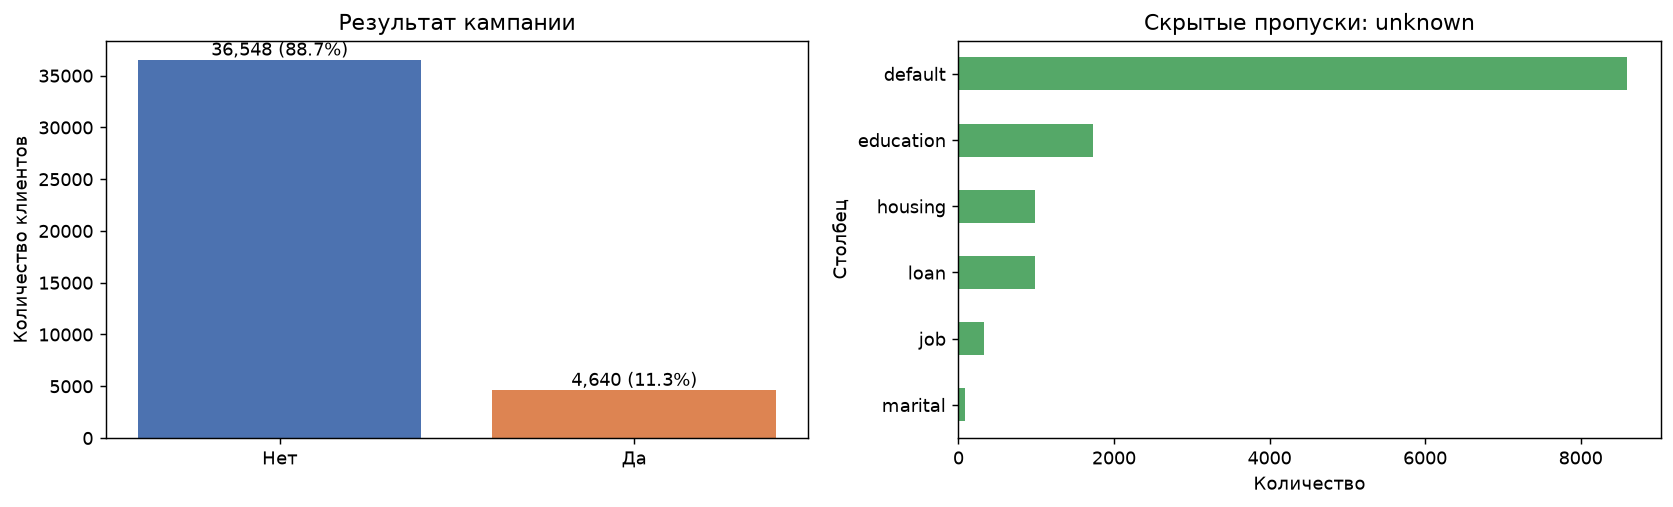

           Количество unknown
default                  8597
education                1731
housing                   990
loan                      990
job                       330
marital                    80

In [ ]:
# EDA: баланс классов, скрытые пропуски и особые значения
unknown_counts = df.select_dtypes(include=["object", "str"]).eq("unknown").sum()
unknown_counts = unknown_counts[unknown_counts > 0].sort_values(ascending=False)

print("Размер данных после удаления duration:", df.shape)
print("Полных дубликатов:", df.duplicated().sum())
print("Явных NaN:", int(df.isna().sum().sum()))
print("Код pdays=999 (клиент ранее не контактировался):", int(df["pdays"].eq(999).sum()))
print("Доля pdays=999: {:.1f}%".format(df["pdays"].eq(999).mean() * 100))
print("Неизвестные значения по столбцам:")
display(unknown_counts.rename("Количество unknown").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts = df["y"].value_counts().reindex(["no", "yes"])
axes[0].bar(["Нет", "Да"], counts.values, color=["#4c72b0", "#dd8452"])
axes[0].set(title="Результат кампании", ylabel="Количество клиентов")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 400, f"{v:,} ({v/len(df):.1%})", ha="center", fontsize=10)
unknown_counts.sort_values().plot(kind="barh", ax=axes[1], color="#55a868")
axes[1].set(title="Скрытые пропуски: unknown", xlabel="Количество", ylabel="Столбец")
plt.tight_layout()
plt.show()

**Наблюдения.** Пустых `NaN` нет, но `unknown` встречается в шести категориальных столбцах. Класс `yes` составляет около 11% выборки — классы несбалансированы. Значение `pdays = 999` — специальный код «ранее не контактировался», поэтому это не обычный выброс и его смысл нужно сохранить. В исходной таблице до удаления duration было 12 полностью одинаковых строк. После удаления duration в `df` обнаруживается 1 784 повторяющиеся строки; автоматически их не удаляем, чтобы не менять выборку и распределение классов команды.

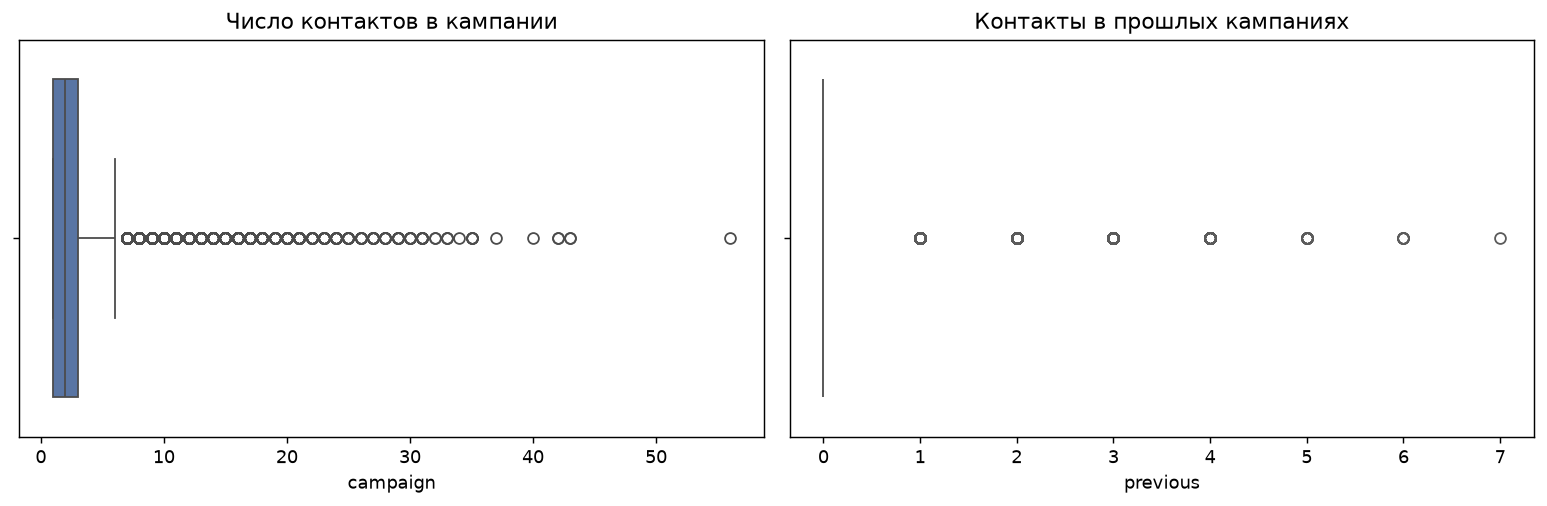

          95-й перцентиль  Максимум  Выше 95-го перцентиля
campaign              7.0        56                   1423
previous              1.0         7                    861

In [ ]:
# Посмотрим на хвосты числовых признаков, не удаляя их автоматически
outlier_summary = pd.DataFrame({
    "95-й перцентиль": X_train[["campaign", "previous"]].quantile(0.95),
    "Максимум": X_train[["campaign", "previous"]].max(),
    "Выше 95-го перцентиля": [
        int((X_train["campaign"] > X_train["campaign"].quantile(0.95)).sum()),
        int((X_train["previous"] > X_train["previous"].quantile(0.95)).sum()),
    ],
})
display(outlier_summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=X_train["campaign"], ax=axes[0], color="#4c72b0")
axes[0].set(title="Число контактов в кампании", xlabel="campaign")
sns.boxplot(x=X_train["previous"], ax=axes[1], color="#dd8452")
axes[1].set(title="Контакты в прошлых кампаниях", xlabel="previous")
plt.tight_layout()
plt.show()

## ColumnTransformer и Pipeline

В предыдущей ячейке участник 1 уже выполнил stratified train/test split. Значения `unknown` преобразуем в пропуски отдельно в обеих выборках; сами правила заполнения, масштабирования и кодирования будут обучаться только внутри Pipeline на `X_train`.

In [ ]:
# Подготовим копии: исходные X_train и X_test из части участника 1 не меняем
X_train_pipe = X_train.replace("unknown", np.nan).copy()
X_test_pipe = X_test.replace("unknown", np.nan).copy()

numeric_features = X_train_pipe.select_dtypes(include="number").columns.tolist()
categorical_features = X_train_pipe.select_dtypes(exclude="number").columns.tolist()
print(f"Числовые признаки ({len(numeric_features)}): {numeric_features}")
print(f"Категориальные признаки ({len(categorical_features)}): {categorical_features}")
print("duration среди признаков:", "duration" in X_train_pipe.columns)

Числовые признаки (9): ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Категориальные признаки (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
duration среди признаков: False


In [ ]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features),
], remainder="drop")

# Модель здесь нужна как финальный шаг Pipeline; оценка метрик относится к другим участникам.
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])
pipeline.fit(X_train_pipe, y_train)
train_matrix = pipeline.named_steps["preprocessor"].transform(X_train_pipe)
test_matrix = pipeline.named_steps["preprocessor"].transform(X_test_pipe)
print("Размер преобразованной train-матрицы:", train_matrix.shape)
print("Размер преобразованной test-матрицы:", test_matrix.shape)
print("Pipeline обучен на train; test только преобразован.")

Размер преобразованной train-матрицы: (32950, 56)
Размер преобразованной test-матрицы: (8238, 56)
Pipeline обучен на train; test только преобразован.


## Почему здесь нет утечки данных

- `duration` исключён до разбиения данных участником 1: он становится известен только после телефонного разговора.
- Split уже выполнен до настройки препроцессинга.
- `SimpleImputer`, `StandardScaler` и `OneHotEncoder` входят в `Pipeline`; их параметры вычисляются при `pipeline.fit(X_train_pipe, y_train)`.
- Для теста используется уже обученный преобразователь. `handle_unknown="ignore"` позволяет обработать категорию, которой не было в train.
- В этой части не сравниваются модели и не рассчитывается качество: это задачи участников 2 и 4.